# Steady overturning with dissipative basal sliding

This calculation seeks a counterexample to the proposed statement that a dissipative sliding law prevents isochrone overturning in steady full-Stokes flow.

## Model and boundary conditions

The model is two-dimensional, incompressible, Newtonian ice with density $917\,\mathrm{kg\,m^{-3}}$ and viscosity $2.5\times10^8\,\mathrm{Pa\,yr}$. A traction-free plane surface crosses a smooth circular trough that is $150$ m deep. Gravity acts at a surface slope of $0.05$ rad. The bed is impermeable and obeys the constant linear law $u_t=C\tau_b$, with $C=10^{-5}\,\mathrm{m\,yr^{-1}\,Pa^{-1}}$. Hence the bed always removes mechanical energy: $P_b=-\int_{\Gamma_b}u_t^2/C\,\mathrm{d}s<0$. No velocity is prescribed.

The steady surface mass balance is diagnosed from the computed normal velocity: $\dot a=-w_s$. It is positive on the upstream surface and negative on the downstream surface. The prediction being tested is that particles deposited in upstream order acquire $\partial x/\partial x_0|_\tau<0$ before they re-emerge in the ablation zone.

## Numerical and topology checks

The notebook reports the gravity, viscous, and basal power balance; the basal-law and no-penetration residuals; mesh convergence of the material-map Jacobian; and source-spacing and time-step convergence. It also reports the minimum horizontal speed over every velocity degree of freedom and along every traced trajectory. A positive domain-wide minimum excludes a closed recirculation cell in the resolved flow.

,target spacing (m),cells,min J at fold age,max J at fold age,min J when overturned,basal dissipation / gravity power,relative energy residual,relative basal-law residual,rms basal normal speed (m/yr),minimum trajectory u (m/yr),minimum nodal u (m/yr)
0,15,547,-0.084473,0.0267377,-0.223719,0.980205,1.79941e-05,0.00358606,4.76818e-07,0.101506,0.100467
1,10,1190,-0.084508,0.0266917,-0.223753,0.980221,2.93634e-06,0.00191416,1.57271e-07,0.101506,0.100468
2,7.5,2128,-0.0845099,0.0266877,-0.223758,0.980223,6.67084e-07,0.001211,6.49195e-08,0.101506,0.100467


,surface origins,time step (yr),min J at fold age,max J at fold age
0,121,2,-0.0826468,0.0261973
1,241,1,-0.0845099,0.0266877
2,481,0.5,-0.0849726,0.0269161


Parameters: {'surface slope (rad)': 0.05, 'linear mobility (m yr^-1 Pa^-1)': 1e-05, 'viscosity (Pa yr)': 250000000.0, 'fold age (yr)': np.float64(1657.191024288295), 'overturned age (yr)': np.float64(1815.0187408871802), 'surface accumulation range (m/yr)': (np.float64(0.018882790622059942), np.float64(0.21267378978873874))}


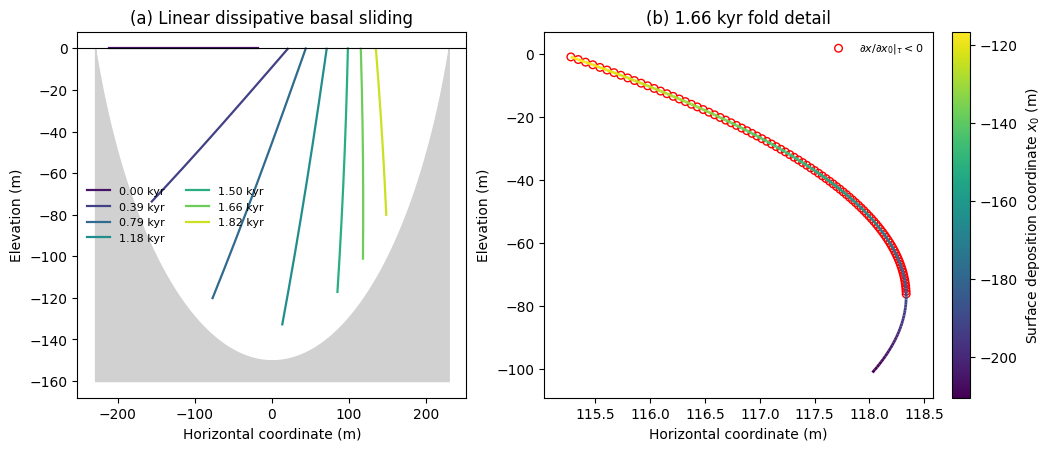

In [1]:
%matplotlib inline
"""Steady full-Stokes overturning with passive linear basal sliding."""

from pathlib import Path
import logging
import tempfile
import warnings

warnings.filterwarnings("ignore", message="Unable to import recommended hash")
warnings.filterwarnings("ignore", message="The .*Function.at.* method")
logging.getLogger("tsfc").setLevel(logging.ERROR)

import firedrake as fd
import gmsh
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.interpolate import RegularGridInterpolator

plt.rcParams["ps.fonttype"] = 42
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 220)
pd.set_option("display.float_format", lambda value: f"{value:.6g}")


DENSITY = 917.0
GRAVITY = 9.81
VISCOSITY = 2.5e8  # Pa yr
SURFACE_SLOPE = 0.05
BASAL_DRAG = 1.0e5  # Pa yr m^-1
CENTER_HEIGHT = 100.0  # m above the surface
VERTICAL_RADIUS = 250.0  # m
HORIZONTAL_RADIUS = 250.0  # m
NITSCHE_PENALTY = 3.0e4


def cap_mesh(resolution):
    """Mesh a circular bed beneath a flat accumulation--ablation surface."""
    half_width = HORIZONTAL_RADIUS * np.sqrt(
        1.0 - (CENTER_HEIGHT / VERTICAL_RADIUS) ** 2
    )
    mesh_file = tempfile.NamedTemporaryFile(suffix=".msh", delete=False).name
    gmsh.initialize()
    gmsh.option.setNumber("General.Terminal", 0)
    gmsh.option.setNumber("Mesh.MshFileVersion", 2.2)
    gmsh.model.add("circular_cap")
    left = gmsh.model.geo.addPoint(-half_width, 0.0, 0.0, resolution)
    bottom = gmsh.model.geo.addPoint(
        0.0, CENTER_HEIGHT - VERTICAL_RADIUS, 0.0, resolution
    )
    right = gmsh.model.geo.addPoint(half_width, 0.0, 0.0, resolution)
    center = gmsh.model.geo.addPoint(0.0, CENTER_HEIGHT, 0.0, resolution)
    if HORIZONTAL_RADIUS == VERTICAL_RADIUS:
        bed_left = gmsh.model.geo.addCircleArc(left, center, bottom)
        bed_right = gmsh.model.geo.addCircleArc(bottom, center, right)
    else:
        major = gmsh.model.geo.addPoint(
            HORIZONTAL_RADIUS, CENTER_HEIGHT, 0.0, resolution
        )
        bed_left = gmsh.model.geo.addEllipseArc(left, center, major, bottom)
        bed_right = gmsh.model.geo.addEllipseArc(bottom, center, major, right)
    surface = gmsh.model.geo.addLine(right, left)
    loop = gmsh.model.geo.addCurveLoop([bed_left, bed_right, surface])
    area = gmsh.model.geo.addPlaneSurface([loop])
    gmsh.model.geo.synchronize()
    gmsh.model.addPhysicalGroup(1, [bed_left, bed_right], 1)
    gmsh.model.addPhysicalGroup(1, [surface], 2)
    gmsh.model.addPhysicalGroup(2, [area], 1)
    gmsh.model.mesh.generate(2)
    gmsh.write(mesh_file)
    gmsh.finalize()
    linear_mesh = fd.Mesh(mesh_file)
    coordinate_space = fd.VectorFunctionSpace(linear_mesh, "CG", 2)
    coordinates = fd.Function(coordinate_space).interpolate(
        fd.SpatialCoordinate(linear_mesh)
    )
    bed_nodes = fd.DirichletBC(
        coordinate_space, fd.Constant((0.0, 0.0)), 1
    ).nodes
    bed_coordinates = coordinates.dat.data[bed_nodes]
    relative = bed_coordinates - np.array((0.0, CENTER_HEIGHT))
    angle = np.arctan2(
        relative[:, 1] / VERTICAL_RADIUS,
        relative[:, 0] / HORIZONTAL_RADIUS,
    )
    projected = np.column_stack(
        (
            HORIZONTAL_RADIUS * np.cos(angle),
            CENTER_HEIGHT + VERTICAL_RADIUS * np.sin(angle),
        )
    )
    coordinates.dat.data[bed_nodes] = projected
    return fd.Mesh(coordinates)


SOLVER_PARAMETERS = {
    "ksp_type": "preonly",
    "pc_type": "lu",
    "pc_factor_mat_solver_type": "mumps",
}


def solve_stokes(resolution):
    """Solve gravity-driven Stokes flow with constant linear basal drag."""
    mesh = cap_mesh(resolution)
    velocity_space = fd.VectorFunctionSpace(mesh, "CG", 2)
    pressure_space = fd.FunctionSpace(mesh, "CG", 1)
    mixed_space = velocity_space * pressure_space
    solution = fd.Function(mixed_space)
    u, p = fd.split(solution)
    v, q = fd.TestFunctions(mixed_space)
    strain = fd.sym(fd.grad(u))
    body_force = fd.Constant(
        (
            DENSITY * GRAVITY * np.sin(SURFACE_SLOPE),
            -DENSITY * GRAVITY * np.cos(SURFACE_SLOPE),
        )
    )
    residual = (
        2.0 * VISCOSITY * fd.inner(strain, fd.sym(fd.grad(v)))
        - p * fd.div(v)
        - q * fd.div(u)
        - fd.dot(body_force, v)
    ) * fd.dx

    normal = fd.FacetNormal(mesh)
    tangent = fd.as_vector((-normal[1], normal[0]))
    identity = fd.Identity(2)
    stress = 2.0 * VISCOSITY * fd.sym(fd.grad(u)) - p * identity
    test_stress = 2.0 * VISCOSITY * fd.sym(fd.grad(v)) - q * identity
    normal_speed = fd.dot(u, normal)
    test_normal_speed = fd.dot(v, normal)
    cell_size = fd.Constant(resolution)
    residual += (
        BASAL_DRAG * fd.dot(u, tangent) * fd.dot(v, tangent)
        - fd.dot(stress * normal, normal) * test_normal_speed
        - fd.dot(test_stress * normal, normal) * normal_speed
        + NITSCHE_PENALTY * VISCOSITY / cell_size * normal_speed * test_normal_speed
    ) * fd.ds(1)

    rigid_rotation = fd.as_vector(
        (
            CENTER_HEIGHT - fd.SpatialCoordinate(mesh)[1],
            fd.SpatialCoordinate(mesh)[0],
        )
    )
    solution.sub(0).interpolate(fd.Constant(1.0e-3) * rigid_rotation)
    fd.solve(residual == 0, solution, solver_parameters=SOLVER_PARAMETERS)
    velocity, pressure = solution.subfunctions
    bed_length = fd.assemble(fd.Constant(1.0) * fd.ds(1, domain=mesh))
    basal_speed = fd.dot(velocity, tangent)
    physical_stress = (
        2.0 * VISCOSITY * fd.sym(fd.grad(velocity))
        - pressure * fd.Identity(2)
    )
    basal_law_residual = (
        fd.dot(physical_stress * normal, tangent) + BASAL_DRAG * basal_speed
    )
    basal_stress_scale = np.sqrt(
        fd.assemble((BASAL_DRAG * basal_speed) ** 2 * fd.ds(1)) / bed_length
    )
    basal_dissipation = fd.assemble(BASAL_DRAG * basal_speed**2 * fd.ds(1))
    gravity_power = fd.assemble(fd.dot(body_force, velocity) * fd.dx)
    viscous_dissipation = fd.assemble(
        2.0
        * VISCOSITY
        * fd.inner(fd.sym(fd.grad(velocity)), fd.sym(fd.grad(velocity)))
        * fd.dx
    )
    rms_normal_speed = np.sqrt(
        fd.assemble(fd.dot(velocity, normal) ** 2 * fd.ds(1)) / bed_length
    )
    diagnostics = {
        "gravity power": gravity_power,
        "basal dissipation": basal_dissipation,
        "viscous dissipation": viscous_dissipation,
        "relative energy residual": (
            gravity_power - basal_dissipation - viscous_dissipation
        )
        / gravity_power,
        "rms basal normal speed": rms_normal_speed,
        "bed length": bed_length,
        "rms basal tangential speed": np.sqrt(
            fd.assemble(basal_speed**2 * fd.ds(1)) / bed_length
        ),
        "rotation rate": fd.assemble(
            fd.dot(velocity, rigid_rotation) * fd.ds(1)
        )
        / fd.assemble(fd.dot(rigid_rotation, rigid_rotation) * fd.ds(1)),
        "relative basal-law residual": np.sqrt(
            fd.assemble(basal_law_residual**2 * fd.ds(1)) / bed_length
        )
        / basal_stress_scale,
        "minimum nodal horizontal speed": np.min(velocity.dat.data_ro[:, 0]),
        "cells": mesh.num_cells(),
    }
    return mesh, velocity, diagnostics


def bed_height(x):
    return CENTER_HEIGHT - VERTICAL_RADIUS * np.sqrt(
        1.0 - (np.asarray(x) / HORIZONTAL_RADIUS) ** 2
    )


def make_sampler(velocity):
    """Interpolate the finite-element solution in surface-following coordinates."""
    half_width = HORIZONTAL_RADIUS * np.sqrt(
        1.0 - (CENTER_HEIGHT / VERTICAL_RADIUS) ** 2
    )
    x = np.linspace(-0.98 * half_width, 0.98 * half_width, 501)
    sigma = np.linspace(0.005, 0.9999, 141)
    bed = bed_height(x)
    X = np.tile(x, (len(sigma), 1))
    Z = bed[None, :] * (1.0 - sigma[:, None])
    points = np.column_stack((X.ravel(), Z.ravel()))
    velocity_values = np.asarray(
        velocity.at(points, tolerance=1.0e-7)
    ).reshape(Z.shape + (2,))
    fields = {
        "u": velocity_values[..., 0],
        "w": velocity_values[..., 1],
    }
    interpolators = {
        name: RegularGridInterpolator(
            (sigma, x), values, bounds_error=False, fill_value=np.nan
        )
        for name, values in fields.items()
    }

    def sample(name, x_value, z_value):
        x_values, z_values = np.broadcast_arrays(x_value, z_value)
        bed_values = bed_height(x_values)
        sigma_values = (z_values - bed_values) / (-bed_values)
        points = np.column_stack((sigma_values.ravel(), x_values.ravel()))
        values = interpolators[name](points).reshape(x_values.shape)
        return float(values) if values.ndim == 0 else values

    return sample, half_width


def trace_material_map(
    sample, half_width, output_ages, time_step=1.0, source_count=241
):
    """Advect the surface-deposition map with a vectorized Runge--Kutta step."""
    sources = np.linspace(-0.92 * half_width, -0.08 * half_width, source_count)
    tiny_depth = 5.0e-2
    surface_w = sample("w", sources, -tiny_depth)
    sources = sources[surface_w < 0.0]
    state = np.column_stack((sources, np.full_like(sources, -tiny_depth)))

    def velocity_values(values):
        return np.column_stack(
            (
                sample("u", values[:, 0], values[:, 1]),
                sample("w", values[:, 0], values[:, 1]),
            )
        )

    snapshots = {0.0: state.copy()}
    current_time = 0.0
    minimum_horizontal_speed = np.inf
    for output_age in output_ages[1:]:
        while current_time < output_age - 1.0e-10:
            step = min(time_step, output_age - current_time)
            k1 = velocity_values(state)
            minimum_horizontal_speed = min(
                minimum_horizontal_speed, np.nanmin(k1[:, 0])
            )
            k2 = velocity_values(state + 0.5 * step * k1)
            k3 = velocity_values(state + 0.5 * step * k2)
            k4 = velocity_values(state + step * k3)
            state += step * (k1 + 2.0 * k2 + 2.0 * k3 + k4) / 6.0
            current_time += step
        snapshots[output_age] = state.copy()
    accumulation = -sample("w", sources, -tiny_depth)
    return sources, snapshots, minimum_horizontal_speed, accumulation


def valid_jacobian(sources, states):
    jacobian = np.gradient(states[:, 0], sources)
    valid = (
        np.isfinite(jacobian)
        & (states[:, 1] < -0.01)
        & (states[:, 1] > bed_height(states[:, 0]) + 0.01)
    )
    return jacobian, valid


mesh_resolutions = [15.0, 10.0, 7.5]
solutions = [solve_stokes(resolution) for resolution in mesh_resolutions]
reference_diagnostics = solutions[-1][2]
quarter_turn = 0.5 * np.pi / reference_diagnostics["rotation rate"]
age_factors = np.array([0.0, 0.25, 0.50, 0.75, 0.95, 1.05, 1.15])
ages = age_factors * quarter_turn

maps = []
convergence_rows = []
for resolution, (mesh, velocity, diagnostics) in zip(
    mesh_resolutions, solutions
):
    sample, half_width = make_sampler(velocity)
    sources, snapshots, minimum_speed, accumulation = trace_material_map(
        sample, half_width, ages
    )
    fold_jacobian, fold_valid = valid_jacobian(sources, snapshots[ages[-2]])
    overturned_jacobian, overturned_valid = valid_jacobian(
        sources, snapshots[ages[-1]]
    )
    convergence_rows.append(
        {
            "target spacing (m)": resolution,
            "cells": diagnostics["cells"],
            "min J at fold age": np.min(fold_jacobian[fold_valid]),
            "max J at fold age": np.max(fold_jacobian[fold_valid]),
            "min J when overturned": np.min(
                overturned_jacobian[overturned_valid]
            ),
            "basal dissipation / gravity power": diagnostics[
                "basal dissipation"
            ]
            / diagnostics["gravity power"],
            "relative energy residual": diagnostics[
                "relative energy residual"
            ],
            "relative basal-law residual": diagnostics[
                "relative basal-law residual"
            ],
            "rms basal normal speed (m/yr)": diagnostics[
                "rms basal normal speed"
            ],
            "minimum trajectory u (m/yr)": minimum_speed,
            "minimum nodal u (m/yr)": diagnostics[
                "minimum nodal horizontal speed"
            ],
        }
    )
    maps.append((sources, snapshots, accumulation))

convergence = pd.DataFrame(convergence_rows)
display(convergence)
sources, snapshots, accumulation = maps[-1]

map_rows = []
for source_count, time_step in [(121, 2.0), (241, 1.0), (481, 0.5)]:
    test_sources, test_snapshots, _, _ = trace_material_map(
        sample,
        half_width,
        ages,
        time_step=time_step,
        source_count=source_count,
    )
    test_jacobian, test_valid = valid_jacobian(
        test_sources, test_snapshots[ages[-2]]
    )
    map_rows.append(
        {
            "surface origins": source_count,
            "time step (yr)": time_step,
            "min J at fold age": np.min(test_jacobian[test_valid]),
            "max J at fold age": np.max(test_jacobian[test_valid]),
        }
    )
display(pd.DataFrame(map_rows))
print(
    "Parameters:",
    {
        "surface slope (rad)": SURFACE_SLOPE,
        "linear mobility (m yr^-1 Pa^-1)": 1.0 / BASAL_DRAG,
        "viscosity (Pa yr)": VISCOSITY,
        "fold age (yr)": ages[-2],
        "overturned age (yr)": ages[-1],
        "surface accumulation range (m/yr)": (
            np.min(accumulation),
            np.max(accumulation),
        ),
    },
)

half_width = HORIZONTAL_RADIUS * np.sqrt(
    1.0 - (CENTER_HEIGHT / VERTICAL_RADIUS) ** 2
)
figure, axes = plt.subplots(1, 2, figsize=(10.4, 4.4), constrained_layout=True)
bed_x = np.linspace(-half_width, half_width, 600)
axes[0].fill_between(
    bed_x, bed_height(bed_x), np.min(bed_height(bed_x)) - 10.0, color="0.82"
)
colors = plt.cm.viridis(np.linspace(0.05, 0.92, len(ages)))
for age, color in zip(ages, colors):
    states = snapshots[age]
    axes[0].plot(
        states[:, 0],
        states[:, 1],
        lw=1.6,
        color=color,
        label=f"{age / 1000:.2f} kyr",
    )
axes[0].axhline(0.0, color="k", lw=0.8)
axes[0].set(xlabel="Horizontal coordinate (m)", ylabel="Elevation (m)")
axes[0].legend(frameon=False, ncol=2, fontsize=8)
axes[0].set_title("(a) Linear dissipative basal sliding")

fold_states = snapshots[ages[-2]]
fold_jacobian, fold_valid = valid_jacobian(sources, fold_states)
fold_points = fold_states[fold_valid]
fold_sources = sources[fold_valid]
fold_jacobian = fold_jacobian[fold_valid]
segments = np.stack((fold_points[:-1], fold_points[1:]), axis=1)
collection = LineCollection(segments, cmap="viridis", linewidth=2.0)
collection.set_array(0.5 * (fold_sources[:-1] + fold_sources[1:]))
axes[1].add_collection(collection)
negative = fold_jacobian < 0.0
axes[1].scatter(
    fold_points[negative, 0],
    fold_points[negative, 1],
    s=30,
    facecolors="none",
    edgecolors="red",
    linewidths=1.0,
    label=r"$\partial x/\partial x_0|_\tau<0$",
)
axes[1].autoscale()
axes[1].margins(0.08)
axes[1].set(xlabel="Horizontal coordinate (m)", ylabel="Elevation (m)")
axes[1].set_title(f"(b) {ages[-2] / 1000:.2f} kyr fold detail")
axes[1].legend(frameon=False, loc="upper right", fontsize=8)
colorbar = figure.colorbar(collection, ax=axes[1], pad=0.02)
colorbar.set_label("Surface deposition coordinate $x_0$ (m)")

figure_directory = Path("../figures")
figure_directory.mkdir(exist_ok=True)
for suffix in ("eps", "pdf"):
    figure.savefig(figure_directory / f"dissipative_sliding_counterexample.{suffix}")
figure.savefig(figure_directory / "dissipative_sliding_counterexample.png", dpi=220)
for suffix in ("eps", "pdf"):
    figure.savefig(figure_directory / f"Figure7.{suffix}")
figure.savefig(figure_directory / "Figure7.png", dpi=220)
plt.show()
